
# External Tg data: does more data reduce the Tg error?

*Author: Suhmi. Builds on notebooks 07 and 08.*

## Purpose

Notebooks 08 and 09 showed that the Tg error is limited by the amount of data (408 training
polymers), not by the model. This notebook adds an external, curated Tg dataset to the
**training** data and measures the effect in cross-validation.

## Data source

**Curated Glass Transition Temperature for Polymers** (LAMALAB, Friedrich Schiller University
Jena), Kunchapu, S. & Jablonka, K. M., Zenodo record 15210035, licence **CC-BY 4.0**.
7,367 polymers with experimental Tg (in K), each with its source, the number of reported
values, their standard deviation and a reliability flag. Saved in `data/external/`.

## Rules

- **The validation subsets are frozen.** Every external polymer that matches a Tg validation
  polymer (same structure, or Tanimoto similarity ≥ 0.95) is removed before anything else.
- External polymers are used **only for training**. All scores are calculated on our own Tg
  training polymers with the same five folds, so they are directly comparable with
  notebooks 07–09.
- Where a polymer has Tg in both datasets, our label is kept and the external one is dropped.


## 1. Setup

In [1]:

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

# Make the project's src package importable from the notebooks folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.polymer_features import SHAPE_COLUMNS, build_chain_features, build_features
from src.shape_cache import compute_shape_cache

RDLogger.DisableLog("rdApp.*")

RANDOM_STATE = 42
VALIDATION_FRACTION = 0.20
N_FOLDS = 5

target_columns = ["Tg", "FFV", "Tc", "Density", "Rg"]
TG = target_columns.index("Tg")


def canonical(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(mol) if mol is not None else None


## 2. Our data: splits and folds (unchanged)

In [2]:

train = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "train.csv")
train["canonical"] = train["SMILES"].apply(canonical)
labels = train[target_columns].to_numpy(dtype=float)
cv_folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

labelled = train.index[train["Tg"].notna()]
tg_train_index, tg_valid_index = train_test_split(
    labelled, test_size=VALIDATION_FRACTION, random_state=RANDOM_STATE, shuffle=True
)
tg_train = np.asarray(tg_train_index)
tg_valid = np.asarray(tg_valid_index)   # used only to remove matching external polymers
tg_folds = [tg_train[test_idx] for _, test_idx in cv_folds.split(tg_train)]
assert len(tg_train) == 408
print(f"Tg training polymers: {len(tg_train)}, Tg validation polymers (frozen): {len(tg_valid)}")


Tg training polymers: 408, Tg validation polymers (frozen): 103



## 3. Cleaning the external data

1. Convert Tg from K to °C.
2. Keep only reliable values: flags **black** (one source) and **gold** (several sources that
   agree); drop **yellow** and **red** (several sources that disagree).
3. Merge duplicate structures (mean Tg).
4. **Remove every polymer that matches a Tg validation polymer.**
5. Compare with our labels where both datasets have Tg, then drop those external values.


In [3]:

external_raw = pd.read_csv(PROJECT_ROOT / "data" / "external" /
                           "LAMALAB_CURATED_Tg_structured_polymerclass.csv")
external = pd.DataFrame({
    "SMILES": external_raw["PSMILES_not_canonicalize"],
    "Tg": external_raw["labels.Exp_Tg(K)"] - 273.15,
    "reliability": external_raw["meta.reliability"],
    "source": external_raw["meta.source"],
})
external["canonical"] = external["SMILES"].apply(canonical)
steps = {"downloaded": len(external)}

print("Reliability flags:", external["reliability"].value_counts().to_dict())
external = external[external["reliability"].isin(["black", "gold"]) & external["canonical"].notna()]
steps["reliable (black/gold)"] = len(external)

external = (external.groupby("canonical", as_index=False)
            .agg(SMILES=("SMILES", "first"), Tg=("Tg", "mean")))
steps["unique structures"] = len(external)

# Remove matches with the Tg validation polymers: same structure or very similar fingerprint
_, fingerprints_ours = build_features(train["SMILES"])
_, fingerprints_external = build_features(external["SMILES"])


def tanimoto(a, b):
    common = a @ b.T
    return common / (a.sum(axis=1)[:, None] + b.sum(axis=1)[None, :] - common)


bits_valid = fingerprints_ours.loc[tg_valid].to_numpy(dtype=float)
max_similarity_to_valid = tanimoto(fingerprints_external.to_numpy(dtype=float), bits_valid).max(axis=1)
same_as_valid = external["canonical"].isin(train.loc[tg_valid, "canonical"]).to_numpy()
leak = same_as_valid | (max_similarity_to_valid >= 0.95)
print(f"Matches with Tg validation polymers: {same_as_valid.sum()} identical, "
      f"{(leak & ~same_as_valid).sum()} near-identical (Tanimoto ≥ 0.95) -> removed")
external = external[~leak].reset_index(drop=True)
steps["after removing validation matches"] = len(external)

# Polymers with Tg in both datasets: compare, then keep our label
ours = train.loc[tg_train, ["canonical", "Tg"]]
both = ours.merge(external[["canonical", "Tg"]], on="canonical", suffixes=("_ours", "_external"))
difference = both["Tg_external"] - both["Tg_ours"]
print(f"Polymers with Tg in both datasets: {len(both)}; "
      f"median difference (external − ours) {difference.median():.1f} °C, "
      f"mean absolute difference {difference.abs().mean():.1f} °C, "
      f"correlation {both['Tg_ours'].corr(both['Tg_external']):.3f}")
external = external[~external["canonical"].isin(ours["canonical"])].reset_index(drop=True)
steps["after removing our Tg training polymers"] = len(external)

display(pd.Series(steps, name="external polymers").to_frame())
in_our_data = external["canonical"].isin(train["canonical"]).sum()
print(f"{in_our_data} of the remaining external polymers are in our data without a Tg label")


Reliability flags: {'black': 7088, 'gold': 143, 'yellow': 132, 'red': 4}


Matches with Tg validation polymers: 1 identical, 24 near-identical (Tanimoto ≥ 0.95) -> removed
Polymers with Tg in both datasets: 6; median difference (external − ours) -24.9 °C, mean absolute difference 35.0 °C, correlation 0.978


,external polymers
downloaded,7367
reliable (black/gold),7231
unique structures,7225
after removing validation matches,7200
after removing our Tg training polymers,7194


5088 of the remaining external polymers are in our data without a Tg label


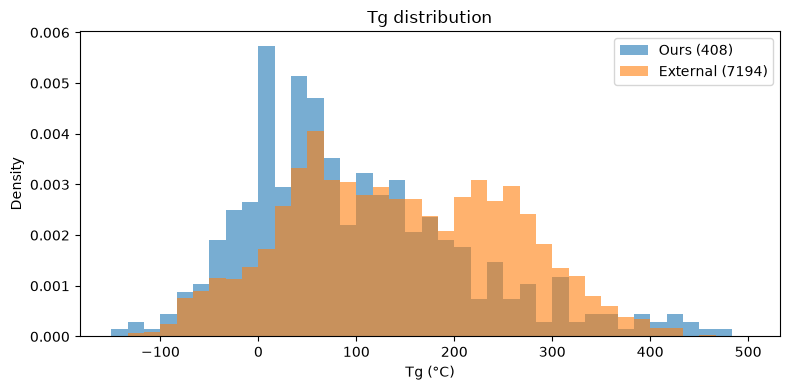

Mean Tg: ours 99 °C, external 144 °C


In [4]:

# Tg distributions: our training polymers vs. the cleaned external data
plt.figure(figsize=(8, 4))
bins = np.linspace(-150, 500, 40)
plt.hist(labels[tg_train, TG], bins=bins, density=True, alpha=0.6, label=f"Ours ({len(tg_train)})")
plt.hist(external["Tg"], bins=bins, density=True, alpha=0.6, label=f"External ({len(external)})")
plt.xlabel("Tg (°C)")
plt.ylabel("Density")
plt.title("Tg distribution")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Mean Tg: ours {labels[tg_train, TG].mean():.0f} °C, external {external['Tg'].mean():.0f} °C")



## 4. Features for the external polymers

The same 73 descriptors and 1,024 fingerprint bits as for our data. The 3D shape descriptors
of the external polymers are cached in `data/processed/external_tg_shape_descriptors.csv`.


In [5]:

def descriptor_table(smiles, shape):
    bplus, fingerprints = build_features(smiles)
    chain = build_chain_features(smiles)
    return pd.concat([bplus, chain, shape, fingerprints], axis=1)


shape_ours = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "shape_descriptors.csv",
                         index_col=0)[SHAPE_COLUMNS]
features_ours = descriptor_table(train["SMILES"], shape_ours)

# Polymers that are also in our data reuse our cached 3D descriptors; the rest are calculated once
shape_by_canonical = shape_ours.groupby(train["canonical"]).first()
new_structures = external.loc[~external["canonical"].isin(shape_by_canonical.index), ["SMILES", "canonical"]]

EXTERNAL_SMILES = PROJECT_ROOT / "data" / "processed" / "external_tg_smiles.csv"
EXTERNAL_SHAPE = PROJECT_ROOT / "data" / "processed" / "external_tg_shape_descriptors.csv"
if not EXTERNAL_SHAPE.exists():
    new_structures.to_csv(EXTERNAL_SMILES, index=False)
    start = time.time()
    _, crashed = compute_shape_cache(EXTERNAL_SMILES, EXTERNAL_SHAPE)
    print(f"3D descriptors calculated in {time.time() - start:.0f} s; crashed rows: {len(crashed)}")
new_shape = pd.read_csv(EXTERNAL_SHAPE, index_col=0)[SHAPE_COLUMNS]
new_shape.index = pd.read_csv(EXTERNAL_SMILES)["canonical"]
shape_external = pd.concat([shape_by_canonical, new_shape]).loc[external["canonical"]]
shape_external.index = external.index
print(f"3D descriptors: {len(external) - len(new_structures)} reused, {len(new_structures)} newly calculated")

features_external = descriptor_table(external["SMILES"], shape_external)
assert list(features_external.columns) == list(features_ours.columns)
X_ours = features_ours.to_numpy(dtype=float)
X_external = features_external.to_numpy(dtype=float)
y_external = external["Tg"].to_numpy()
print("Features:", X_ours.shape[1], "| external polymers:", len(X_external))


3D descriptors: 5088 reused, 2106 newly calculated


Features: 1097 | external polymers: 7194



## 5. Does the external data help? (cross-validation)

For every fold, the model is trained on our fitting polymers, with or without the cleaned
external polymers, and scored on our held-out polymers of that fold. Three XGBoost settings:
the tuned Tg setting (very shallow trees, chosen for 408 polymers), the default setting, and a
deeper setting that can use the larger data set (the MAE-tuned FFV setting from notebook 07,
selected on 5,624 polymers).


In [6]:

xgboost_settings = {
    "tuned Tg (depth 2)": dict(n_estimators=750, learning_rate=0.013339162948869679, max_depth=2,
                               min_child_weight=1, subsample=0.6550083776583973,
                               colsample_bytree=0.7394663949166917, reg_lambda=7.472397689332939),
    "default (depth 4)": dict(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8,
                              colsample_bytree=0.8),
    "deeper (depth 6)": dict(n_estimators=1077, learning_rate=0.073, max_depth=6, min_child_weight=2,
                             subsample=0.877, colsample_bytree=0.641, reg_lambda=1.25),
}

cv_rows = []
oof_predictions = {}
start = time.time()
for setting, params in xgboost_settings.items():
    for data_name in ["Our data only", "Our data + external"]:
        predictions = pd.Series(index=tg_train, dtype=float)
        for fold in range(N_FOLDS):
            rows = tg_folds[fold]
            fit_rows = np.setdiff1d(tg_train, rows)
            X_fit, y_fit = X_ours[fit_rows], labels[fit_rows, TG]
            if data_name.endswith("external"):
                X_fit = np.vstack([X_fit, X_external])
                y_fit = np.concatenate([y_fit, y_external])
            model = make_pipeline(SimpleImputer(strategy="median"),
                                  XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1))
            y_pred = model.fit(X_fit, y_fit).predict(X_ours[rows])
            predictions.loc[rows] = y_pred

            y_true = labels[rows, TG]
            baseline = np.mean(np.abs(y_true - np.median(labels[fit_rows, TG])))
            mae = mean_absolute_error(y_true, y_pred)
            cv_rows.append({"setting": setting, "data": data_name, "fold": fold, "MAE": mae,
                            "error_reduction": 100 * (1 - mae / baseline),
                            "R2": r2_score(y_true, y_pred), "mean_error": np.mean(y_pred - y_true)})
        oof_predictions[(setting, data_name)] = predictions
    print(f"{setting} done ({time.time() - start:.0f} s)")

cv_df = pd.DataFrame(cv_rows)
cv_summary = cv_df.groupby(["setting", "data"]).agg(
    MAE=("MAE", "mean"), error_reduction=("error_reduction", "mean"),
    error_reduction_std=("error_reduction", "std"), R2=("R2", "mean"),
    mean_error=("mean_error", "mean"))
display(cv_summary.round(2))


tuned Tg (depth 2) done (14 s)


default (depth 4) done (27 s)


deeper (depth 6) done (55 s)


MAE  error_reduction  \
setting            data                                          
deeper (depth 6)   Our data + external  50.14            43.44   
                   Our data only        51.60            41.77   
default (depth 4)  Our data + external  48.59            45.19   
                   Our data only        50.60            42.93   
tuned Tg (depth 2) Our data + external  52.65            40.59   
                   Our data only        48.16            45.62   

                                        error_reduction_std    R2  mean_error  
setting            data                                                        
deeper (depth 6)   Our data + external                 6.42  0.65       20.27  
                   Our data only                       4.84  0.65       -0.51  
default (depth 4)  Our data + external                 6.37  0.66       22.32  
                   Our data only                       4.24  0.66       -0.20  
tuned Tg (depth 2) Our data + external                 4.42  0.62       24.20  
                   Our data only                       2.57  0.69       -0.01

### 5.1 Where does the external data help?

In [7]:

best = cv_summary["MAE"].idxmin()
reference = ("tuned Tg (depth 2)", "Our data only")
print(f"Best: {best[0]}, {best[1]} | reference: {reference[0]}, {reference[1]}")

y_true = pd.Series(labels[tg_train, TG], index=tg_train)
comparison = pd.DataFrame({
    "Tg": y_true,
    "error before": (oof_predictions[reference] - y_true).abs(),
    "error after": (oof_predictions[best] - y_true).abs(),
})
comparison["Tg range"] = pd.qcut(comparison["Tg"], 5, precision=0)

# Similarity of each polymer to its fold's training polymers (our data only, as in notebook 08)
bits = fingerprints_ours.to_numpy(dtype=float)
nearest = pd.Series(index=tg_train, dtype=float)
for fold in range(N_FOLDS):
    rows = tg_folds[fold]
    nearest.loc[rows] = tanimoto(bits[rows], bits[np.setdiff1d(tg_train, rows)]).max(axis=1)
comparison["similarity to our training data"] = pd.cut(nearest, [0, 0.3, 0.5, 0.7, 1.0], include_lowest=True)

for group in ["Tg range", "similarity to our training data"]:
    display(comparison.groupby(group, observed=True).agg(
        polymers=("Tg", "size"), MAE_before=("error before", "mean"),
        MAE_after=("error after", "mean")).round(1))

slope = np.polyfit(y_true, oof_predictions[best], 1)[0]
print(f"Slope of predicted vs. actual Tg: {slope:.2f} (was 0.69 in notebook 08)")


Best: tuned Tg (depth 2), Our data only | reference: tuned Tg (depth 2), Our data only


,polymers,MAE_before,MAE_after
Tg range,,,
"(-149.0, 5.0]",82,60.9,60.9
"(5.0, 51.0]",81,35.0,35.0
"(51.0, 107.0]",82,34.1,34.1
"(107.0, 185.0]",81,48.8,48.8
"(185.0, 472.0]",82,61.8,61.8


,polymers,MAE_before,MAE_after
similarity to our training data,,,
"(-0.001, 0.3]",36,60.1,60.1
"(0.3, 0.5]",179,46.8,46.8
"(0.5, 0.7]",137,50.7,50.7
"(0.7, 1.0]",56,38.8,38.8


Slope of predicted vs. actual Tg: 0.67 (was 0.69 in notebook 08)


## 6. Correcting for the difference between the datasets

With the external data, all models predict our polymers about 20–24 °C too high on average
(`mean_error` in section 5). The external Tg values are systematically different from ours
(e.g. different measurement methods or definitions), the same kind of shift that the Kaggle
post-competition report describes. Two standard corrections:

- **Source flag:** an extra feature, 1 for external and 0 for our polymers. The model can learn
  the offset between the datasets; predictions for our polymers use the flag 0.
- **External model as a feature (stacking):** a model trained on the external data only predicts
  Tg for every polymer; this prediction is an extra feature for the model trained on our data only.
  It brings in the external knowledge, while our model learns how it translates to our labels.
  The external polymers contain none of our Tg polymers, so no fold information leaks.


In [8]:

X_ours_flag = np.hstack([X_ours, np.zeros((len(X_ours), 1))])
X_external_flag = np.hstack([X_external, np.ones((len(X_external), 1))])

# Stacking: one external-only model per setting, fixed for all folds
external_feature = {}
for setting, params in xgboost_settings.items():
    model = make_pipeline(SimpleImputer(strategy="median"),
                          XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1))
    external_feature[setting] = model.fit(X_external, y_external).predict(X_ours)[:, None]

correction_rows = []
for setting, params in xgboost_settings.items():
    for variant in ["Our data + external + source flag", "Our data + external-model feature"]:
        predictions = pd.Series(index=tg_train, dtype=float)
        for fold in range(N_FOLDS):
            rows = tg_folds[fold]
            fit_rows = np.setdiff1d(tg_train, rows)
            if variant.endswith("flag"):
                X_fit = np.vstack([X_ours_flag[fit_rows], X_external_flag])
                y_fit = np.concatenate([labels[fit_rows, TG], y_external])
                X_eval = X_ours_flag[rows]
            else:
                X_stacked = np.hstack([X_ours, external_feature[setting]])
                X_fit, y_fit, X_eval = X_stacked[fit_rows], labels[fit_rows, TG], X_stacked[rows]
            model = make_pipeline(SimpleImputer(strategy="median"),
                                  XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1))
            y_pred = model.fit(X_fit, y_fit).predict(X_eval)
            predictions.loc[rows] = y_pred

            y_true = labels[rows, TG]
            baseline = np.mean(np.abs(y_true - np.median(labels[fit_rows, TG])))
            mae = mean_absolute_error(y_true, y_pred)
            correction_rows.append({"setting": setting, "data": variant, "fold": fold, "MAE": mae,
                                    "error_reduction": 100 * (1 - mae / baseline),
                                    "R2": r2_score(y_true, y_pred), "mean_error": np.mean(y_pred - y_true)})
        oof_predictions[(setting, variant)] = predictions

all_df = pd.concat([cv_df, pd.DataFrame(correction_rows)])
all_summary = all_df.groupby(["setting", "data"]).agg(
    MAE=("MAE", "mean"), error_reduction=("error_reduction", "mean"),
    error_reduction_std=("error_reduction", "std"), R2=("R2", "mean"),
    mean_error=("mean_error", "mean"))
display(all_summary.round(2))

# Correlation of the external-only model with our labels (how well it transfers on its own)
for setting in xgboost_settings:
    pred = external_feature[setting][tg_train, 0]
    print(f"External-only model ({setting}) on our Tg polymers: "
          f"MAE {mean_absolute_error(labels[tg_train, TG], pred):.1f} °C, "
          f"mean error {np.mean(pred - labels[tg_train, TG]):.1f} °C, "
          f"correlation {np.corrcoef(pred, labels[tg_train, TG])[0, 1]:.3f}")


MAE  error_reduction  \
setting            data                                                        
deeper (depth 6)   Our data + external                50.14            43.44   
                   Our data + external + source flag  46.63            47.43   
                   Our data + external-model feature  50.33            43.21   
                   Our data only                      51.60            41.77   
default (depth 4)  Our data + external                48.59            45.19   
                   Our data + external + source flag  44.86            49.43   
                   Our data + external-model feature  48.47            45.35   
                   Our data only                      50.60            42.93   
tuned Tg (depth 2) Our data + external                52.65            40.59   
                   Our data + external + source flag  50.18            43.39   
                   Our data + external-model feature  46.80            47.20   
                   Our data only                      48.16            45.62   

                                                      error_reduction_std  \
setting            data                                                     
deeper (depth 6)   Our data + external                               6.42   
                   Our data + external + source flag                 5.34   
                   Our data + external-model feature                 3.63   
                   Our data only                                     4.84   
default (depth 4)  Our data + external                               6.37   
                   Our data + external + source flag                 4.53   
                   Our data + external-model feature                 4.14   
                   Our data only                                     4.24   
tuned Tg (depth 2) Our data + external                               4.42   
                   Our data + external + source flag                 2.76   
                   Our data + external-model feature                 1.09   
                   Our data only                                     2.57   

                                                        R2  mean_error  
setting            data                                                 
deeper (depth 6)   Our data + external                0.65       20.27  
                   Our data + external + source flag  0.69        3.73  
                   Our data + external-model feature  0.66       -1.57  
                   Our data only                      0.65       -0.51  
default (depth 4)  Our data + external                0.66       22.32  
                   Our data + external + source flag  0.72        4.15  
                   Our data + external-model feature  0.67       -0.83  
                   Our data only                      0.66       -0.20  
tuned Tg (depth 2) Our data + external                0.62       24.20  
                   Our data + external + source flag  0.65       12.42  
                   Our data + external-model feature  0.71       -0.73  
                   Our data only                      0.69       -0.01

External-only model (tuned Tg (depth 2)) on our Tg polymers: MAE 54.1 °C, mean error 26.7 °C, correlation 0.815
External-only model (default (depth 4)) on our Tg polymers: MAE 49.7 °C, mean error 25.5 °C, correlation 0.841
External-only model (deeper (depth 6)) on our Tg polymers: MAE 50.7 °C, mean error 24.3 °C, correlation 0.829


In [9]:

best = all_summary["MAE"].idxmin()
print(f"Best: {best[0]}, {best[1]} (MAE {all_summary.loc[best, 'MAE']:.1f} °C, "
      f"error reduction {all_summary.loc[best, 'error_reduction']:.1f}%) | reference MAE "
      f"{all_summary.loc[reference, 'MAE']:.1f} °C")

comparison["error after"] = (oof_predictions[best] - comparison["Tg"]).abs()
for group in ["Tg range", "similarity to our training data"]:
    display(comparison.groupby(group, observed=True).agg(
        polymers=("Tg", "size"), MAE_before=("error before", "mean"),
        MAE_after=("error after", "mean")).round(1))
print(f"Slope of predicted vs. actual Tg: {np.polyfit(comparison["Tg"], oof_predictions[best], 1)[0]:.2f} (was 0.69)")


Best: default (depth 4), Our data + external + source flag (MAE 44.9 °C, error reduction 49.4%) | reference MAE 48.2 °C


,polymers,MAE_before,MAE_after
Tg range,,,
"(-149.0, 5.0]",82,60.9,60.8
"(5.0, 51.0]",81,35.0,35.4
"(51.0, 107.0]",82,34.1,35.8
"(107.0, 185.0]",81,48.8,43.3
"(185.0, 472.0]",82,61.8,49.0


,polymers,MAE_before,MAE_after
similarity to our training data,,,
"(-0.001, 0.3]",36,60.1,59.0
"(0.3, 0.5]",179,46.8,41.8
"(0.5, 0.7]",137,50.7,48.5
"(0.7, 1.0]",56,38.8,36.6


Slope of predicted vs. actual Tg: 0.74 (was 0.69)


## 7. Save the cleaned external data

Used by later notebooks, so the cleaning is done in one place only.

In [10]:

CLEAN_FILE = PROJECT_ROOT / "data" / "processed" / "external_tg_clean.csv"
pd.concat([external[["SMILES", "canonical", "Tg"]], shape_external], axis=1).to_csv(CLEAN_FILE, index=False)
print(f"Saved {len(external)} cleaned external polymers to {CLEAN_FILE.name}")


Saved 7194 cleaned external polymers to external_tg_clean.csv


#### Findings: external Tg data

**Cleaning:** 7,367 external polymers → 7,194 used for training (136 unreliable values, 6 duplicates,
25 matches with our Tg validation polymers and 6 overlaps with our Tg training polymers removed).
5,088 of them are polymers that are in our data without a Tg label.

**The two datasets differ systematically.** A model trained only on the external data predicts our
Tg polymers with a correlation of 0.84, but **about 25 °C too high** on average. Simply adding the
external data therefore makes the predictions too high (+20 to +24 °C) and does not help.

**With a source flag, the external data helps** (cross-validation on our 408 Tg polymers):

| Model | MAE | Error reduction | R² |
|---|---:|---:|---:|
| Tuned XGBoost, our data only (reference) | 48.2 °C | 45.6% | 0.69 |
| Default XGBoost, our data + external | 48.6 °C | 45.2% | 0.66 |
| **Default XGBoost, our data + external + source flag** | **44.9 °C** | **49.4% ± 4.5** | **0.72** |
| Tuned XGBoost, external-model prediction as feature | 46.8 °C | 47.2% ± 1.1 | 0.71 |

- The source flag lets the model learn the offset between the datasets, so it can use the external
  structure–Tg relationships without taking over their level. The MAE falls by 3.3 °C (−7%),
  and the error reduction passes the 40% goal more clearly (49%).
- **The gain is largest where it was needed most:** high-Tg polymers (> 185 °C) 61.8 → 49.0 °C,
  107–185 °C 48.8 → 43.3 °C, and polymers with only moderately similar training examples
  (Tanimoto 0.3–0.5) 46.8 → 41.8 °C. Very low Tg (< 5 °C) does not improve (60.9 → 60.8 °C).
- The shrinkage towards the middle is slightly smaller (slope 0.69 → 0.74).

**Caveats:** the best variant was selected from 12 on the same folds, so the gain is slightly
optimistic (about one fold standard deviation); the XGBoost settings were not re-tuned for the
larger data set; the validation subsets were not used.

**Data source (CC-BY 4.0, must be cited):** Kunchapu, S. & Jablonka, K. M., *Curated Glass Transition
Temperature for Polymers*, Zenodo (2025), https://zenodo.org/records/15210035.
